# Assessing change over time for repeat draw clients
Going to take a look at any change over time for clients with multiple blood draws

In [2]:
import pandas as pd
import arivale_data_interface as adi
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# apply settings so the lib knows where the data is
adi.apply_isb_config()

import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from statannotations.Annotator import Annotator

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
# Now you can import your file
from regression_functions import *

In [3]:
abx_covar = pd.read_csv("../data/rh_abx_covar_alphadivs_scfa.csv", dtype={'public_client_id':str})

In [4]:
abx_covar.days_in_program.max()

769.0

## Use snapshot to select repeat participants

In [5]:
div = adi.get_snapshot("microbiome_diversity")
div.dropna(subset=['days_in_program'], inplace=True)
shannon_div = div[["diversity_shannon", "public_client_id", "days_in_program", "vendor_dashboard", "observed_otus_20000"]]

In [6]:
shannon_div = shannon_div[shannon_div.public_client_id.isin(abx_covar.public_client_id)].sort_values(by='public_client_id')

In [7]:
# Grab the ids that show up more than once
shannon_dup_id = (shannon_div[shannon_div.public_client_id.duplicated()
                  ].public_client_id.tolist())

shannon_dup = shannon_div[shannon_div.public_client_id.isin(shannon_dup_id)]

In [8]:
shannon_dup['public_client_id'].nunique() # Sizeable number!

839

In [9]:
# Now subset these folks from our study
abx_covar_repeat = abx_covar[abx_covar.public_client_id.isin(shannon_dup_id)]
abx_covar_repeat_small = (abx_covar_repeat[[
    'public_client_id', 
    'days_in_program',
    'abx_recency']].copy())

In [10]:
# Want to be able to compare the dates
abx_covar_repeat_small.rename(columns={
    'days_in_program':'days_in_program_questionnaire'}, inplace=True)

In [11]:
shannon_repeats = shannon_dup.merge(
    abx_covar_repeat_small,
    how ='left',
    on="public_client_id")

In [12]:
shannon_repeats.abx_recency.value_counts()

abx_recency
none      1315
twelve     397
three      276
Name: count, dtype: int64

In [13]:
shannon_repeats.public_client_id.nunique()

839

We will want to know whether or not the stool sample in question is associated with the abx questionnaire or not. 

In [14]:
shannon_repeats['paired_stool_questionnare'] = (
    (shannon_repeats['days_in_program'] - shannon_repeats['days_in_program_questionnaire'] <= 30)
    .map({True: 'Yes', False: 'No'}))

In [15]:
shannon_repeats_baseline = shannon_repeats[shannon_repeats['paired_stool_questionnare'] == 'Yes'].drop_duplicates(
    subset='public_client_id')
len(shannon_repeats_baseline)

839

In [16]:
shannon_repeats_followup = shannon_repeats[shannon_repeats['paired_stool_questionnare'] == 'No']

In [17]:
shannon_repeats_followup.sort_values(by=['public_client_id', 'days_in_program'])
shannon_repeats_followup_first = shannon_repeats_followup.drop_duplicates(subset='public_client_id', keep='first')
len(shannon_repeats_followup_first)

831

In [18]:
# Samples at day 2 and 25
# To close to one another
#  Drop this client 

to_drop = list(set(shannon_repeats_baseline.public_client_id) - 
               set(shannon_repeats_followup_first.public_client_id))

# shannon_repeats[shannon_repeats.public_client_id == to_drop[0]]

In [19]:
shannon_repeats_baseline = shannon_repeats_baseline[shannon_repeats_baseline.public_client_id != to_drop[0]]

**Now let's join the data**

In [20]:
all_followup_timepoints = pd.concat([shannon_repeats_baseline, shannon_repeats_followup_first])
# all_followup_timepoints.sort_values(by=['public_client_id','days_in_program']).head() 

<Axes: xlabel='days_in_program', ylabel='diversity_shannon'>

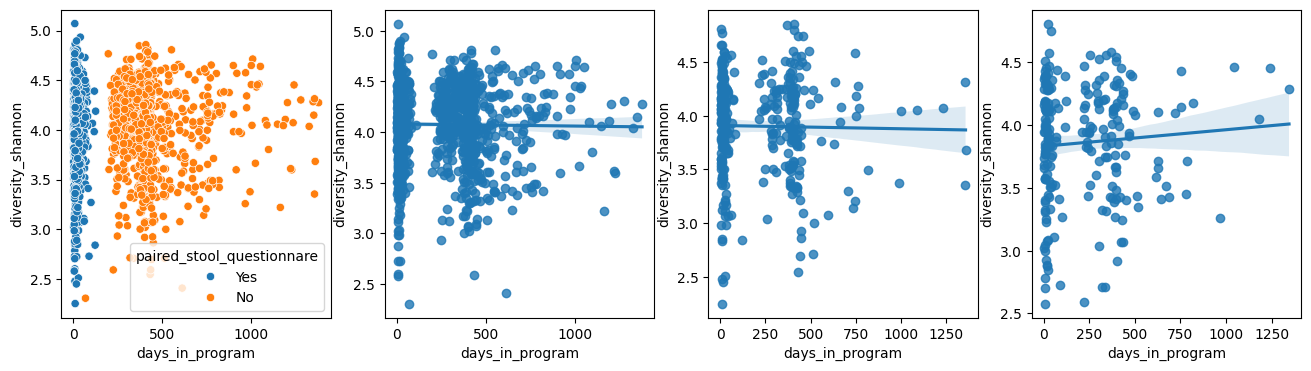

In [21]:
all_followup_timepoints_none = all_followup_timepoints[all_followup_timepoints['abx_recency'] == 'none']
all_followup_timepoints_three = all_followup_timepoints[all_followup_timepoints['abx_recency'] == 'three']
all_followup_timepoints_twelve = all_followup_timepoints[all_followup_timepoints['abx_recency'] == 'twelve']


fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes = axes.flatten()

sns.scatterplot(data=all_followup_timepoints, x='days_in_program', y='diversity_shannon', hue='paired_stool_questionnare', ax=axes[0])
sns.regplot(data=all_followup_timepoints_none, x='days_in_program', y='diversity_shannon', ax=axes[1])
sns.regplot(data=all_followup_timepoints_twelve, x='days_in_program', y='diversity_shannon', ax=axes[2])
sns.regplot(data=all_followup_timepoints_three, x='days_in_program', y='diversity_shannon', ax=axes[3])

# plt.xlabel('Time Point')
# plt.ylabel('diversity_shannon')
# plt.title('Abx users and their follow-ups')
# plt.show()

## Now let's use the alpha diversity measures that we have re-calculated
This is from rarefied data too.

In [22]:
abx_df_obs_feats = (abx_covar[[
    'public_client_id',
    'days_in_program', 
    'observed_features', 
    'berger_parker',
    'shannon_index']].copy())

abx_df_obs_feats.rename(columns={
    'days_in_program':'days_in_program_abx_df'}, inplace=True)

In [23]:
baseline_merge = (shannon_repeats_baseline[[
    'public_client_id',
    'days_in_program',
    'days_in_program_questionnaire',
    'paired_stool_questionnare',
    'abx_recency']].copy())

In [24]:
baseline_alphas = baseline_merge.merge(
    abx_df_obs_feats, 
    how='left',
    on='public_client_id')
baseline_alphas.head()

,public_client_id,days_in_program,days_in_program_questionnaire,paired_stool_questionnare,abx_recency,days_in_program_abx_df,observed_features,berger_parker,shannon_index
0,01002412,13.0,10.0,Yes,none,10.0,121.494626,0.130139,3.388333
1,01003555,8.0,0.0,Yes,none,0.0,85.943252,0.563537,2.115057
2,01003758,21.0,5.0,Yes,none,5.0,85.751037,0.264530,2.824300
3,01004350,23.0,1.0,Yes,none,1.0,71.069951,0.282135,2.901893
4,01004596,7.0,0.0,Yes,none,0.0,80.413747,0.360647,2.811232


In [25]:
sum(baseline_alphas['days_in_program_questionnaire'] == baseline_alphas['days_in_program_abx_df'])

838

In [26]:
# Now we can drop the extra column
baseline_alphas.drop(columns=['days_in_program_abx_df'], inplace=True)

In [27]:
baseline_alphas.abx_recency.value_counts()

abx_recency
none      558
twelve    165
three     115
Name: count, dtype: int64

## Grab follow-up days_in_program

In [28]:
follow_up_small = (shannon_repeats_followup_first[[
    'public_client_id',
    'days_in_program',
    'paired_stool_questionnare',
    'abx_recency']].copy())

## Find follow-up stool samples

In [29]:
asvs = pd.read_csv("/proj/gibbons/arivale_16S/data/asvs.csv")
metadata = pd.read_csv("/proj/gibbons/arivale_16S/data/metadata.csv")
asvs_meta = pd.merge(asvs, metadata[["id", "public_client_id", "sex", "age", "days_in_program"]], on="id")
asvs_meta.head()

,id,hash,count,public_client_id,sex,age,days_in_program
0,22001612560016|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,1285,01884560,F,42.0,8.0
1,22001612560023|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,2431,01192392,F,31.0,3.0
2,22001612560062|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,4908,01349735,F,54.0,8.0
3,22001612560065|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,3944,01735977,F,58.0,16.0
4,22001612560067|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,5990,01363623,F,52.0,11.0


In [30]:
tax = pd.read_csv("/proj/gibbons/arivale_16S/data/taxonomy.csv")
tax = tax.drop("sequence", axis=1).rename(columns={"id": "hash"})
asvs_meta_tax = pd.merge(asvs_meta, tax, on="hash")
asvs_meta_tax.head()

,id,hash,count,public_client_id,sex,age,days_in_program,Kingdom,Phylum,Class,Order,Family,Genus,Species
0,22001612560016|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,1285,01884560,F,42.0,8.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus
1,22001612560023|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,2431,01192392,F,31.0,3.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus
2,22001612560062|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,4908,01349735,F,54.0,8.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus
3,22001612560065|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,3944,01735977,F,58.0,16.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus
4,22001612560067|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,5990,01363623,F,52.0,11.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus


In [31]:
# We have to subset down to only the id/date combinations we're interested in
follow_up_small = follow_up_small.sort_values(by='days_in_program')
asvs_meta_tax = asvs_meta_tax.dropna(
    subset=['public_client_id', 'days_in_program']
).sort_values(by='days_in_program')

asvs_abx = pd.merge_asof(
    asvs_meta_tax, follow_up_small,
    by="public_client_id",
    on="days_in_program",
    direction="nearest", 
    tolerance=30.0).dropna(                     # Keep only folks with 
    subset=['id', 'paired_stool_questionnare']) # stool and abx questionnaire data
asvs_abx.head()

,id,hash,count,public_client_id,sex,age,days_in_program,Kingdom,Phylum,Class,Order,Family,Genus,Species,paired_stool_questionnare,abx_recency
960006,22001612562061|GFM-1079-001,85ec2f8f231099b6ec7056308db3633f,40,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Coprococcus_1,catus,No,none
960038,22001612562061|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,1000,01241681,M,50.0,68.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus,No,none
960066,22001612562061|GFM-1079-001,fe185f1a3fbb60a17ceeef4e07dd84c4,2,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Family_XI,Finegoldia,NaN,No,none
960114,22001612562061|GFM-1079-001,baf976cc1c7d05bc2fce35d438e9914f,3722,01241681,M,50.0,68.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Prevotellaceae,Prevotella_9,NaN,No,none
960129,22001612562061|GFM-1079-001,fcb87043d178c4ee44cb1efef91f6204,40,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,NaN,NaN,No,none


In [32]:
taxa = asvs_abx.drop(columns=["hash"], axis=1)
taxa.head()

,id,count,public_client_id,sex,age,days_in_program,Kingdom,Phylum,Class,Order,Family,Genus,Species,paired_stool_questionnare,abx_recency
960006,22001612562061|GFM-1079-001,40,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Coprococcus_1,catus,No,none
960038,22001612562061|GFM-1079-001,1000,01241681,M,50.0,68.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus,No,none
960066,22001612562061|GFM-1079-001,2,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Family_XI,Finegoldia,NaN,No,none
960114,22001612562061|GFM-1079-001,3722,01241681,M,50.0,68.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Prevotellaceae,Prevotella_9,NaN,No,none
960129,22001612562061|GFM-1079-001,40,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,NaN,NaN,No,none


In [33]:
# Make a new column, similar to before, but exclude the species in the name
taxa = taxa.assign(taxa_genus_level = taxa.Kingdom.astype(str) + '_' + \
                   taxa.Phylum.astype(str) + '_' + taxa.Class.astype(str) + '_' + \
                   taxa.Order.astype(str) + '_' + taxa.Family.astype(str) + '_' + \
                   taxa.Genus.astype(str))
taxa.head()

,id,count,public_client_id,sex,age,days_in_program,Kingdom,Phylum,Class,Order,Family,Genus,Species,paired_stool_questionnare,abx_recency,taxa_genus_level
960006,22001612562061|GFM-1079-001,40,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Coprococcus_1,catus,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_L...
960038,22001612562061|GFM-1079-001,1000,01241681,M,50.0,68.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,vulgatus,No,none,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...
960066,22001612562061|GFM-1079-001,2,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Family_XI,Finegoldia,NaN,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_F...
960114,22001612562061|GFM-1079-001,3722,01241681,M,50.0,68.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Prevotellaceae,Prevotella_9,NaN,No,none,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...
960129,22001612562061|GFM-1079-001,40,01241681,M,50.0,68.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,NaN,NaN,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_L...


In [34]:
# taxa['taxa_genus_level'].nunique()

In [35]:
genera = taxa.groupby(["id", "taxa_genus_level"])["count"].sum().reset_index()
genera.taxa_genus_level.nunique()

463

In [36]:
too_many_nans_genus = taxa['taxa_genus_level'].str.count('_nan') > 3

# Drop those rows
genus_more_specific = taxa[~too_many_nans_genus].sort_values(by = ['public_client_id'])
genus_more_specific.head()

,id,count,public_client_id,sex,age,days_in_program,Kingdom,Phylum,Class,Order,Family,Genus,Species,paired_stool_questionnare,abx_recency,taxa_genus_level
1255670,AV15-2672|AKE029,1693,01002412,F,52.0,296.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Ruminococcaceae,Ruminococcus_2,bromii,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_R...
1255570,AV15-2672|AKE029,102,01002412,F,52.0,296.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Ruminococcaceae,Ruminococcaceae_UCG-003,NaN,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_R...
1255571,AV15-2672|AKE029,92,01002412,F,52.0,296.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Blautia,NaN,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_L...
1255589,AV15-2672|AKE029,299,01002412,F,52.0,296.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Lachnoclostridium,NaN,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_L...
1255591,AV15-2672|AKE029,656,01002412,F,52.0,296.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,NaN,NaN,No,none,Bacteria_Firmicutes_Clostridia_Clostridiales_L...


<Axes: >

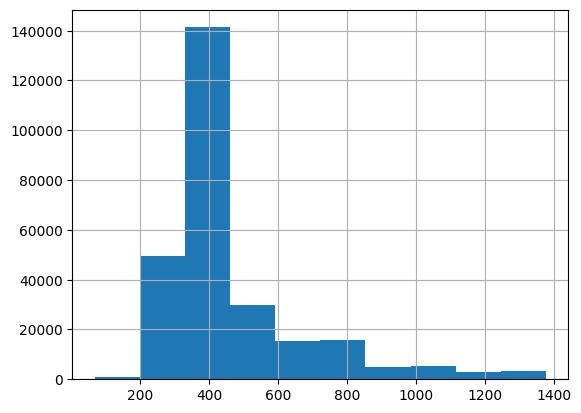

In [37]:
# Before pivoting the table, let's make sure that these dates are large
genus_more_specific.days_in_program.hist()

In [38]:
genus_more_specific.days_in_program.min()

68.0

In [39]:
# Create MultiIndex for pivot table
arrays = [genus_more_specific['public_client_id'], genus_more_specific['taxa_genus_level']]
index = pd.MultiIndex.from_arrays(arrays, names=('public_client_id','taxa_genus_level'))

# Pivot df with taxa as columns, public_client_id as index, and counts as values
taxa_melt_genus = pd.DataFrame(data = {'count': genus_more_specific['count'].to_numpy()}, index=index)

taxa_pivot_genus = taxa_melt_genus.pivot_table(index='public_client_id', columns='taxa_genus_level', 
                                         values='count', aggfunc='sum', fill_value = 0)

taxa_pivot_genus = taxa_pivot_genus.dropna(how='any')
taxa_pivot_genus.head()

taxa_genus_level,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Arcanobacterium,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_F0332,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Mobiluncus,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Trueperella,...,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Verrucomicrobia_Verrucomicrobiae_Chthoniobacterales_Xiphinematobacteraceae_Candidatus_Xiphinematobacter,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Eukaryota_Euglenozoa_Euglenida_Aphagea_Aphagea_fa_Distigma,Eukaryota_Euglenozoa_Euglenida_Aphagea_Aphagea_fa_nan,Eukaryota_Euglenozoa_Euglenida_nan_nan_nan,Eukaryota_Incertae_Sedis_Incertae_Sedis_cl_Incertae_Sedis_or_Incertae_Sedis_fa_Blastocystis
public_client_id,,,,,,,,,,,,,,,,,,,,,
01002412,0,0,0,0,0,10,0,7,0,0,...,0,0,0,0,0,6510,0,0,0,0
01003555,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,65,0,0,0,0
01003758,0,0,0,0,0,10,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
01004350,0,0,0,0,0,0,0,0,0,0,...,20,0,0,0,0,247,0,0,0,0
01004596,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1772,0,0,0,0


In [40]:
taxa_pivot_genus.reset_index(inplace=True)
taxa_pivot_genus.columns.name = None
taxa_pivot_genus

,public_client_id,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Arcanobacterium,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_F0332,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Mobiluncus,...,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Verrucomicrobia_Verrucomicrobiae_Chthoniobacterales_Xiphinematobacteraceae_Candidatus_Xiphinematobacter,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Eukaryota_Euglenozoa_Euglenida_Aphagea_Aphagea_fa_Distigma,Eukaryota_Euglenozoa_Euglenida_Aphagea_Aphagea_fa_nan,Eukaryota_Euglenozoa_Euglenida_nan_nan_nan,Eukaryota_Incertae_Sedis_Incertae_Sedis_cl_Incertae_Sedis_or_Incertae_Sedis_fa_Blastocystis
0,01002412,0,0,0,0,0,10,0,7,0,...,0,0,0,0,0,6510,0,0,0,0
1,01003555,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,65,0,0,0,0
2,01003758,0,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,01004350,0,0,0,0,0,0,0,0,0,...,20,0,0,0,0,247,0,0,0,0
4,01004596,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1772,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
826,01995874,3252,0,0,0,0,0,0,0,0,...,2515,0,0,0,0,20,0,0,0,18
827,01997909,0,0,0,0,0,133,0,0,0,...,0,0,0,0,0,1253,0,0,0,0
828,01998999,57,0,0,0,0,10,0,0,0,...,0,0,0,0,0,422,0,0,0,0
829,HX400498,0,0,0,0,0,0,0,0,0,...,19,0,0,0,0,53,0,0,0,0


In [41]:
eukaryota_cols = taxa_pivot_genus.columns[taxa_pivot_genus.columns.str.contains('Eukaryota')]

In [42]:
taxa_pivot_genus.drop(columns=eukaryota_cols, inplace=True)

In [43]:
taxa_pivot_genus

,public_client_id,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Arcanobacterium,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_F0332,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Mobiluncus,...,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Pyramidobacter,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Synergistes,Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Verrucomicrobia_Verrucomicrobiae_Chthoniobacterales_Xiphinematobacteraceae_Candidatus_Xiphinematobacter,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
0,01002412,0,0,0,0,0,10,0,7,0,...,0,0,0,0,0,0,0,0,0,6510
1,01003555,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,65
2,01003758,0,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,01004350,0,0,0,0,0,0,0,0,0,...,0,0,0,0,20,0,0,0,0,247
4,01004596,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1772
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
826,01995874,3252,0,0,0,0,0,0,0,0,...,0,0,0,602,2515,0,0,0,0,20
827,01997909,0,0,0,0,0,133,0,0,0,...,0,0,0,0,0,0,0,0,0,1253
828,01998999,57,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,422
829,HX400498,0,0,0,0,0,0,0,0,0,...,0,0,0,0,19,0,0,0,0,53


In [44]:
multiple_use = pd.read_csv('../data/abx_multiple_use_df.csv', dtype={'public_client_id':str})

In [51]:
taxa_pivot_genus[~taxa_pivot_genus.public_client_id.isin(multiple_use.public_client_id)]

,public_client_id,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Arcanobacterium,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_F0332,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Mobiluncus,...,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Pyramidobacter,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Synergistes,Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Verrucomicrobia_Verrucomicrobiae_Chthoniobacterales_Xiphinematobacteraceae_Candidatus_Xiphinematobacter,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
0,01002412,0,0,0,0,0,10,0,7,0,...,0,0,0,0,0,0,0,0,0,6510
1,01003555,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,65
2,01003758,0,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,01004350,0,0,0,0,0,0,0,0,0,...,0,0,0,0,20,0,0,0,0,247
4,01004596,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1772
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
826,01995874,3252,0,0,0,0,0,0,0,0,...,0,0,0,602,2515,0,0,0,0,20
827,01997909,0,0,0,0,0,133,0,0,0,...,0,0,0,0,0,0,0,0,0,1253
828,01998999,57,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,422
829,HX400498,0,0,0,0,0,0,0,0,0,...,0,0,0,0,19,0,0,0,0,53


In [52]:
taxa_pivot_genus.to_csv("../data/repeat_client_follow_up_genera_counts.csv", index=False)

# Now go to R and rareify!

In [44]:
# Used vegan to calculate our alpha diversity metrics
# followup_alphas = pd.read_csv("../data/abx_followups_alphadivs_rarefied.csv", dtype={'public_client_id':str})

In [ ]:
# oops I didn't keep the dates when I took this to R, we should merge them back!
followup_alphas = follow_up_small.merge(followup_alphas, how='left', on='public_client_id')
followup_alphas_long = followup_alphas.copy()

In [ ]:
followup_alphas.days_in_program.mean()

### Make both long and wide form df

In [ ]:
# Now going to try and make long_df to use in a lmm
followup_alphas_long.rename(columns={'observed_features_followup':'observed_features'}, inplace=True)
followup_alphas_long.rename(columns={'shannon_index_followup':'shannon_index'}, inplace=True)
followup_alphas_long.rename(columns={'berger_parker_followup':'berger_parker'}, inplace=True)

In [ ]:
# First let's drop the helper paired stool column from both questionnaires
baseline_alphas.drop(columns='paired_stool_questionnare', inplace=True)
followup_alphas_long.drop(columns='paired_stool_questionnare', inplace=True)

baseline_alphas.drop(columns='days_in_program_questionnaire', inplace=True)

Okay now the follow-up here has the same column names as the baseline.

Check the wide forget follow-up next.

In [ ]:
followup_alphas.drop(columns=['paired_stool_questionnare','abx_recency'], inplace=True)
followup_alphas.rename(columns={'days_in_program':'days_in_program_followup'}, inplace=True)

In [ ]:
# followup_alphas

In [ ]:
followup_baselines_all = baseline_alphas.merge(followup_alphas, how='left', on='public_client_id') # used in wide df

In [ ]:
followup_baselines_all.abx_recency.value_counts()

Okay let's switch back to the long-df generation. make a copy of the baseline df just in case.

In [ ]:
baseline_alphas_long = baseline_alphas.copy()

In [ ]:
abx_covar_followups = abx_covar[['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
                                 'meds_blood_sugar', 'meds_cholesterol', 'sex', 'age',
                                 'centered_eGFR','abx_recency_three', 'abx_recency_twelve']].copy()

abx_covar_followups = abx_covar_followups[abx_covar_followups.public_client_id.isin(baseline_alphas_long.public_client_id)]

In [ ]:
baseline_alphas_long = baseline_alphas_long.merge(abx_covar_followups, how='left', on='public_client_id')
followup_alphas_long = followup_alphas_long.merge(abx_covar_followups, how='left', on='public_client_id')

In [ ]:
# Make a days_since_baseline column
baseline_alphas_long.set_index('public_client_id', inplace=True)
followup_alphas_long.set_index('public_client_id', inplace=True)

In [ ]:
baseline_alphas_long.loc[:,'dsb'] = 0
followup_alphas_long.loc[:,'dsb'] = followup_alphas_long.loc[:,'days_in_program'] - baseline_alphas_long.loc[:,'days_in_program']

In [ ]:
followup_alphas_long.dsb.mean() 

In [ ]:
followup_alphas_long.dsb.median()

In [ ]:
fu_long_df = pd.concat([baseline_alphas_long, followup_alphas_long], axis=0)

In [ ]:
fu_long_df.sort_values(by=['public_client_id','days_in_program']).head()

Awesome, the above shows that the says since baseline was calculated appropriately. 

In [ ]:
vendor_df = shannon_repeats[['public_client_id','days_in_program','vendor_dashboard']].copy()

In [ ]:
vendor_df = vendor_df.sort_values(by='days_in_program')
fu_long_df = fu_long_df.sort_values(by='days_in_program')
long_df = pd.merge_asof(
    fu_long_df, 
    vendor_df,
    on='days_in_program',
    by='public_client_id').sort_values(
    by=['public_client_id','days_in_program'])

For some reason vendor information was not available for all folks' second time sample, so we will drop those individuals.

In [ ]:
drop_na_vendor = long_df[long_df.vendor_dashboard.isna()].public_client_id.tolist()
len(drop_na_vendor)

In [ ]:
long_df = long_df[~long_df.public_client_id.isin(drop_na_vendor)]

In [ ]:
## Add BMI as something that changed over time

In [ ]:
weights = adi.get_snapshot("weight")[[
    "BMI_CALC",
    "public_client_id",
    "days_in_program"]].dropna()

In [ ]:
weights = weights.sort_values(by='days_in_program')
long_df = long_df.sort_values(by='days_in_program')

long_bmi = pd.merge_asof(
    long_df, 
    weights,
    on='days_in_program',
    by='public_client_id')

In [ ]:
drop_na_bmi = long_bmi[long_bmi.BMI_CALC.isna()].public_client_id.tolist()
len(drop_na_bmi)

In [ ]:
long_bmi = long_bmi[~long_bmi.public_client_id.isin(drop_na_bmi)]

Let's do some visualization of the two time points.

### Visualization

In [ ]:
long_bmi = long_bmi.sort_values(['public_client_id', 'dsb'])
long_bmi['sample_number'] = long_bmi.groupby('public_client_id').cumcount()
lp_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#808080'} 

plt.figure(figsize=(4,5))

# Draw lines (this is the magic)
sns.lineplot(
    data=long_bmi,
    x='sample_number',
    y='observed_features',
    hue='abx_recency',
    units='public_client_id',  # tells seaborn: one line per subject
    estimator=None,            # prevents averaging
    alpha=0.5,
    palette=lp_pal,
    legend=True
)

# Overlay points
sns.scatterplot(
    data=long_bmi,
    x='sample_number',
    y='observed_features',
    hue='abx_recency',
    palette=lp_pal,
    legend=False
)

plt.xticks([0, 1], ['Baseline', 'Follow up'])
plt.ylabel('Observed Features')
plt.title('Observed Features: Baseline and Follow-Up Stool Samples')

plt.show()

Interestingly, there's a group of people whose observed features completely tank in the second sample. Let's investigate this.

### Investigate outliers

In [ ]:
under_thirtyfive = long_bmi[long_bmi.observed_features < 35].sort_values(
    by=['vendor_dashboard', 'days_in_program'])[[
    'public_client_id',
    'days_in_program',
    'observed_features',
    'vendor_dashboard',
    'abx_recency'
    ]].copy()
under_thirtyfive.head()

In [ ]:
under_thirtyfive.observed_features.mean()

**Interestingly, this is all mostly Second Genome**

In [ ]:
under_thirtyfive[under_thirtyfive.vendor_dashboard == 'Second Genome'].days_in_program.describe()

In [ ]:
(long_bmi[(long_bmi.vendor_dashboard == 'Second Genome') & (long_bmi.days_in_program > 200)]) # ['observed_features'].hist()

In [ ]:
(long_bmi[~(long_bmi.vendor_dashboard == 'Second Genome')])['observed_features'].hist()

In [ ]:
long_bmi[long_bmi.vendor_dashboard == 'Second Genome']['observed_features'].hist()

Interestingly, when we examine this table, all but one of the samples come from the Second Genome vendor. Not sure if that should be a coincendence?

It looks like the samples were collected between day in program 219 and 358. We can go ahead and ask later if these folks were in one batch/if there was a problem with sequencing that was previously addressed.

In [ ]:
sus_fu_ids = long_bmi[long_bmi.observed_features < 35].public_client_id.tolist()

**Look at their first stool samples**

In [ ]:
long_bmi[long_bmi.public_client_id.isin(sus_fu_ids)].sort_values(
    by=['public_client_id','days_in_program'])[[
    'public_client_id',
    'days_in_program',
    'observed_features',
    'vendor_dashboard',
    'abx_recency'
    ]].head()

Hmm let's compare the first and second reads for these individuals!

**Look at the number of reads for these samples**

In [ ]:
hash_counts_first = (asvs_meta_tax[
                     (asvs_meta_tax['public_client_id'] == '01983426') & 
                     (asvs_meta_tax['days_in_program'] == 8.0)]
                     ['count']).sum()

hash_counts_second = (asvs_meta_tax[
                     (asvs_meta_tax['public_client_id'] == '01983426') & 
                     (asvs_meta_tax['days_in_program'] == 231.0)]
                     ['count']).sum()

print(f'First sample processed reads: {hash_counts_first} versus second {hash_counts_second}')

Hmmm, that does seem like a significant difference in the number of reads. Not sure if all cases will be that dramatic though, as this person only had 4 observed features.

**Okay let's try to do this a little more systematically**

In [ ]:
outliers = long_bmi[long_bmi.public_client_id.isin(sus_fu_ids)].sort_values(
    by=['public_client_id','days_in_program'])[[
    'public_client_id',
    'days_in_program',
    'observed_features',
    'vendor_dashboard',
    'abx_recency'
    ]].copy()

outliers.set_index(['public_client_id','days_in_program'], inplace=True)

In [ ]:
outliers.observed_features.mean()

In [ ]:
get_counts = asvs_meta_tax[['public_client_id', 'days_in_program', 'count']].copy()
get_counts.set_index(['public_client_id','days_in_program'], inplace=True)

In [ ]:
merged = get_counts.merge(
    outliers,
    left_index=True,
    right_index=True,
    how="inner"
)

merged=merged.reset_index()

In [ ]:
counts = merged.groupby(
    ['public_client_id','days_in_program'], as_index=False).agg(
    {'count': 'sum'})

In [ ]:
counts = counts.sort_values(by='days_in_program')
long_bmi = long_bmi.sort_values(by='days_in_program')

counts_alphas_sus = pd.merge_asof(counts, 
                                  (long_bmi.iloc[:, 0:6]).copy(),
                                  by='public_client_id',
                                  on='days_in_program',
                                  direction='nearest')

In [ ]:
counts_alphas_sus = counts_alphas_sus.sort_values(['public_client_id', 'days_in_program'])
counts_alphas_sus['timepoint'] = counts_alphas_sus.groupby('public_client_id').cumcount() + 1

df_wide = counts_alphas_sus.pivot_table(
    index='public_client_id',
    columns='timepoint',
    values=['count', 'observed_features', 'berger_parker', 'shannon_index']
)

df_wide.columns = ['_'.join([str(col[0]), str(col[1])]) if isinstance(col, tuple) else col for col in df_wide.columns]

In [ ]:
df_wide['delta_count'] = df_wide['count_2'] - df_wide['count_1']

In [ ]:
df_wide.delta_count.mean()

# questionable = ['01822070', '01241681', '01771190']
# abx_covar[abx_covar.public_client_id.isin(questionable)].iloc[:, 0:20]

`df_wide` will allow us to see the change in ASV count and diversity metrics between the two sample timepoints.

**Let's look at taxonomy**

In [ ]:
asvs_meta_tax_small = asvs_meta_tax.copy()

In [ ]:
asvs_meta_tax_small = asvs_meta_tax_small.assign(
    taxa_genus_level = 
    asvs_meta_tax_small.Kingdom.astype(str) + '_' +
    asvs_meta_tax_small.Phylum.astype(str) + '_' + 
    asvs_meta_tax_small.Class.astype(str) + '_' +
    asvs_meta_tax_small.Order.astype(str) + '_' +
    asvs_meta_tax_small.Family.astype(str) + '_' +
    asvs_meta_tax_small.Genus.astype(str))
asvs_meta_tax_small.head()

In [ ]:
asvs_meta_tax_small = asvs_meta_tax_small[['public_client_id','days_in_program','taxa_genus_level', 'Genus', 'count']]

In [ ]:
asvs_meta_tax_small[asvs_meta_tax_small['public_client_id'] == '01983426']

In [ ]:
small_followup = (asvs_meta_tax_small[(asvs_meta_tax_small['public_client_id'] == '01983426') & 
                  (asvs_meta_tax_small['days_in_program'] == 231.0)])

In [ ]:
first_baseline = (asvs_meta_tax_small[(asvs_meta_tax_small['public_client_id'] == '01983426') & 
                  (asvs_meta_tax_small['days_in_program'] == 8.0)]).groupby(
    "taxa_genus_level", as_index=False).agg({
    "count": "sum",
    "public_client_id": "first",
    "days_in_program": "first",
    "Genus":"first"
      })

In [ ]:
taxa_first = set(first_baseline.taxa_genus_level)
taxa_second = set(small_followup.taxa_genus_level)

In [ ]:
shared = list(taxa_second.intersection(taxa_first))

In [ ]:
small_followup[small_followup.taxa_genus_level.isin(shared)].sort_values(by=["Genus","count"]) # .taxa_genus_level.tolist()

In [ ]:
first_baseline[first_baseline.taxa_genus_level.isin(shared)].sort_values(by=["Genus","count"])

In [ ]:
first_baseline.sort_values(by=["Genus","count"]).taxa_genus_level.nunique() # Rarefied number ~ 76

### Drop these outliers

Okay, well, I am not very confident that I know what's going on with those samples, so let's drop them since it could be anything from concurrent antibiotics to pcr/processing errors.

In [ ]:
long_bmi = long_bmi[~long_bmi.public_client_id.isin(sus_fu_ids)]

In [ ]:
len(sus_fu_ids)

In [ ]:
long_bmi

In [ ]:
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}

sns.set_style(style="whitegrid")

row_order=["three", "twelve", "none"]
palette_map = {
    "three": ["#ccdbdc", "green"],
    "twelve": ["#80ced7", "green"],
    "none": ["#007ea7", "green"],
}

g = sns.displot(
    data=long_bmi, x="observed_features", hue="sample_number",
    row="abx_recency", row_order=row_order,
    kind="kde", height=2.5, aspect=3.5, common_norm=False,
    fill=True, linewidth=3, alpha=0.4,
)


# for ax, level in zip(g.axes.flat, row_order):
#     subset = long_bmi[long_bmi["abx_recency"] == level]
    
#     sns.kdeplot(
#         data=subset,
#         x="observed_features",
#         hue="sample_number",
#         palette=palette_map[level],   # <- per-row palette
#         ax=ax,
#         common_norm=False
#     )

plt.savefig("../figures/stool_follow_up_facet_dist.pdf", bbox_inches="tight")
plt.show()

## Save final stool follow up CSV

In [ ]:
long_bmi.to_csv('../data/stool_repeat_clients_long.csv', index=False)

**Also just in case, let's also look at the person who seems to have not changed at all (twelve month group).**

In [ ]:
long_bmi[long_bmi.observed_features > 155].sort_values(by='public_client_id').iloc[:, 0:6]

This is really cool to see actually. Even though person '01606409' has always had high richness, their earlier timepoint was characterized by more dominance, which would make sence if they were closer in time to the antibiotic perturbation. 

## Is there anything that makes these individuals different from one another? 
- Can look at their diet
- Look at their other covariates, age, sex BMI, etc.

In [ ]:
diet = pd.read_csv("data/diet_collapsed.csv", dtype={'public_client_id':str})

In [ ]:
# Subset to only those in our follow up data
diet = diet[diet.public_client_id.isin(long_bmi.public_client_id)]

### My first attempt will be to look at the people who fill out the questionnaire 2 times
This is because since the individuals were being coached, they may be changing their lifestyle and dietary behaviors. 

In [ ]:
diet_repeats = diet[diet.groupby(
    'public_client_id')['public_client_id'].transform('count') == 2]

In [ ]:
# Next I am interested in only columns that are mostly filled out
threshold = 100
nan_counts = diet_repeats.isna().sum()
columns_to_drop = nan_counts[nan_counts > threshold].index.tolist()

In [ ]:
diet_repeats = diet_repeats.drop(columns=columns_to_drop)
diet_repeats = diet_repeats.drop(columns='response_percentage')

In [ ]:
# Check if controlling by vendor will still be important
diet_repeats.sort_values(
    by=['public_client_id','days_in_program']).vendor.value_counts()

Let's look at the data to compare if people changed much.

In [ ]:
(diet_repeats[[
    'public_client_id',
    'days_in_program',
    'assessment:lifestyle:vegetables:enum']].sort_values(
    by=['public_client_id','days_in_program']))

In [ ]:
diet_repeats.columns

### Let's clean the column names and recode the responses

In [ ]:
col_to_rename = diet_repeats.iloc[:,3:].columns.tolist()
new_col_names = {col: col.split(':')[2] for col in col_to_rename}
diet_repeats.rename(columns=new_col_names, inplace=True)

In [ ]:
diet_repeats.rename(columns={
    'achohol_type': 'alcohol_type', 
    'cruciferous_vegetables':'cruciferous_vegetables_frequency',
    'fruits':'fruits_per_day',
    'vegetables':'vegetables_per_day',
    'sugary_drinks':'sugary_drinks_per_day',
    'water':'cups_water_per_day', 
    'grains':'grains_per_day'}, inplace=True)
diet_repeats.columns

#### Dictionary

In [ ]:
def map_survey_responses(value, mapping_dict):
    """Map a survey response to a category based on a dictionary, keeping NaNs intact."""
    if pd.isna(value):  # Ensure NaNs remain as NaNs
        return np.nan  
    
    value = str(value)  # Convert to string for dictionary lookup
    
    for key, category in mapping_dict.items():
        if value in key:
            return category
    return value  # Return original value if not in the dictionary

In [ ]:
column_mappings = {
    'fruits_per_day': {
        '(0) Zero/less than 1 per day': 0,
        '(1) 1': 1,  
        '(2) 2-3': 2.5,
        ('(3) 4-5', '(4) 6 or more'): 4.5},
    'vegetables_per_day': {
        '(0) Zero/less than 1 per day': 0,
        '(1) 1': 1,
        '(2) 2-3': 2.5,
        ('(3) 4-5', '(4) 6 or more'): 4.5},
    'sugary_drinks_per_day': {
        '(0) Zero/less than 1 per day': 0,
        '(1) 1': 1,
        '(2) 2-3': 2.5,
        ('(3) 4-5', '(4) 6 or more'): 4.5},
    'alcohol_drinks_a_day': {
        '(0) I do not drink': 0, 
        '(1) 1-2 drinks': 1.5,
        ('(2) 3-4 drinks', '(3) 5-6 drinks', '(4) More than 6 drinks'): 3.5},
    'grains_per_day': {
        '(0) Zero/less than 1 per day': 0,
        '(1) 1-2': 1.5,
        '(2) 3-4': 3.5,
        ('(3) 5-6','(4) 7 or more'): 5.5}, 
    'cruciferous_vegetables_frequency': {
        '(4) Less than once per month': 0,      
        '(3) Once per month': 1/30,      
        '(2) Once per week': 1/7, 
        '(1) 3-4 times per week': 3.5/7,
        '(0) Daily': 7/7}, 
    'breakfast': {
        ('(4) Less than once per month','(3) Once per month'): 1/30,
        '(2) Once per week': 1/7,
        '(1) 3-4 times per week': 3.5/7,
        '(0) Daily': 7/7},
    'snack': {
        '(4) Less than once per month': 0,
        '(3) Once per month': 1/30,
        '(2) Once per week': 1/7,
        '(1) 3-4 times per week': 3.5/7,
        '(0) Daily': 7/7}
    }

# Apply the mapping to each column
for col, mapping_dict in column_mappings.items():
    diet_repeats[col] = diet_repeats[col].apply(map_survey_responses, args=(mapping_dict,))
diet_repeats.columns

In [ ]:
# Drop redundant or small group columns
diet_repeats.drop(columns=[
    'alcohol_days_a_week',
    'diet',
    'cups_water_per_day'], inplace=True)
diet_repeats

#### Merge and save

In [ ]:
diet_repeats = diet_repeats.sort_values('days_in_program')
long_bmi = long_bmi.sort_values('days_in_program')

# Merge by nearest time within each id
stool_diet = pd.merge_asof(
    diet_repeats,
    long_bmi,
    on='days_in_program',
    by='public_client_id',
    direction='nearest'
)

In [ ]:
stool_diet.columns

In [ ]:
# stool_diet.isna().sum()

In [ ]:
# stool_diet.to_csv('data/stool_diet_followup.csv', index=False)

## Change focus to look at baseline diet only
Unfortunately, only having around ~300 individuals reduced our power. Let's go back and collect as many clients as we can that filled our the dietary questionnaire at the beginning of their participation in the program (this would be close to the abx questionnaire).

In [ ]:
# Let's grab the baseline dates
baseline_abx_dates = baseline_merge[['public_client_id', 'days_in_program']].copy()
baseline_abx_dates = baseline_abx_dates.sort_values('days_in_program')

diet = diet.sort_values('days_in_program')

# Merge by nearest time within each id
diet_baseline = pd.merge_asof(
    baseline_abx_dates,
    diet,
    by='public_client_id',
    on='days_in_program',
    direction='nearest', 
    tolerance=30
)

In [ ]:
# Go through the same cleaning steps above
threshold = 100
nan_counts = diet_baseline.isna().sum()
columns_to_drop = nan_counts[nan_counts > threshold].index.tolist()

In [ ]:
nan_counts = diet_baseline.isna().sum()
nan_counts

In [ ]:
diet_baseline = diet_baseline.drop(columns=columns_to_drop)
diet_baseline = diet_baseline.drop(columns='response_percentage')

In [ ]:
diet_baseline

In [ ]:
col_to_rename = diet_baseline.iloc[:,3:].columns.tolist()
new_col_names = {col: col.split(':')[2] for col in col_to_rename}
diet_baseline.rename(columns=new_col_names, inplace=True)

In [ ]:
diet_baseline.rename(columns={
    'achohol_type': 'alcohol_type', 
    'cruciferous_vegetables':'cruciferous_vegetables_frequency',
    'fruits':'fruits_per_day',
    'vegetables':'vegetables_per_day',
    'sugary_drinks':'sugary_drinks_per_day',
    'water':'cups_water_per_day', 
    'grains':'grains_per_day'}, inplace=True)
diet_baseline.columns

In [ ]:
for col, mapping_dict in column_mappings.items():
    diet_baseline[col] = diet_baseline[col].apply(map_survey_responses, args=(mapping_dict,))
diet_baseline.columns

In [ ]:
# Drop redundant or small group columns
diet_baseline.drop(columns=[
    'alcohol_days_a_week',
    'diet',
    'cups_water_per_day',
    'snack'], inplace=True)

In [ ]:
diet_baseline.vegetables_per_day.value_counts()

In [ ]:
# diet_baseline = diet_baseline.dropna()

In [ ]:
diet_baseline = diet_baseline[diet_baseline['public_client_id'].isin(
    long_bmi['public_client_id'])].copy()

diet_baseline.drop(columns=['days_in_program'], inplace=True)

long_diet = long_bmi.merge(
    diet_baseline,
    on='public_client_id',
    how='left').dropna()

In [ ]:
long_diet.sort_values(by=['public_client_id','days_in_program'])

In [ ]:
long_diet.groupby('public_client_id')['public_client_id'].count().describe()

## Check diet group sizes
Noticed that there was some high collinearity when I tried 

In [ ]:
diet_cols = ['alcohol_type','breakfast', 'cruciferous_vegetables_frequency',
             'fruits_per_day', 'vegetables_per_day',
             'sugary_drinks_per_day', 'alcohol_drinks_a_day', 'grains_per_day']

In [ ]:
melted = long_diet.melt(
    id_vars=['abx_recency'],
    value_vars=diet_cols,
    var_name='diet_question',
    value_name='behavior')

counts = (melted
    .groupby(['behavior', 'diet_question', 'abx_recency'])
    .size()
    .reset_index(name='count'))

diet_bin_enumeration = counts.pivot_table(
    index=['diet_question', 'behavior'],
    columns='abx_recency',
    values='count',
    fill_value=0)
diet_bin_enumeration

In [ ]:
#long_diet.to_csv('../data/stool_repeat_diet_baseline_only.csv', index=False)

Okay well, unfortunately, we are also not powered enough for this. Sarcasrtic smile :D actually sad :(

Let's start over with the data processing. Try binarized!

In [ ]:
# Let's grab the baseline dates
baseline_abx_dates = baseline_merge[['public_client_id', 'days_in_program']].copy()
baseline_abx_dates = baseline_abx_dates.sort_values('days_in_program')

diet = diet.sort_values('days_in_program')

# Merge by nearest time within each id
diet_baseline = pd.merge_asof(
    baseline_abx_dates,
    diet,
    by='public_client_id',
    on='days_in_program',
    direction='nearest', 
    tolerance=30
)

In [ ]:
diet_baseline = diet_baseline[diet_baseline.public_client_id.isin(long_bmi.public_client_id)]

In [ ]:
# Go through the same cleaning steps above
threshold = 100
nan_counts = diet_baseline.isna().sum()
columns_to_drop = nan_counts[nan_counts > threshold].index.tolist()

In [ ]:
diet_baseline = diet_baseline.drop(columns=columns_to_drop)
diet_baseline = diet_baseline.drop(columns='response_percentage')

In [ ]:
col_to_rename = diet_baseline.iloc[:,3:].columns.tolist()
new_col_names = {col: col.split(':')[2] for col in col_to_rename}
diet_baseline.rename(columns=new_col_names, inplace=True)

In [ ]:
diet_baseline.rename(columns={
    'achohol_type': 'alcohol_type', 
    'cruciferous_vegetables':'cruciferous_vegetables_frequency',
    'fruits':'fruits_per_day',
    'vegetables':'vegetables_per_day',
    'sugary_drinks':'sugary_drinks_per_day',
    'water':'cups_water_per_day', 
    'grains':'grains_per_day'}, inplace=True)
diet_baseline.columns

In [ ]:
column_mappings_binary = {
    'fruits_per_day': {('(0) Zero/less than 1 per day'): 0,
                       ('(1) 1', '(2) 2-3', '(3) 4-5', '(4) 6 or more'): 1},
    'vegetables_per_day': {('(0) Zero/less than 1 per day'): 0,
                           ('(1) 1', '(2) 2-3', '(3) 4-5', '(4) 6 or more'): 1},
    'sugary_drinks_per_day': {('(0) Zero/less than 1 per day'): 0,
                              ('(1) 1', '(2) 2-3', '(3) 4-5', '(4) 6 or more'): 1},
    'alcohol_drinks_a_day': {('(0) I do not drink'): 0, 
                             ('(1) 1-2 drinks', '(2) 3-4 drinks','(3) 5-6 drinks','(4) More than 6 drinks'): 1},
    'grains_per_day': {('(0) Zero/less than 1 per day'): 0,
                       ('(1) 1-2', '(2) 3-4','(3) 5-6','(4) 7 or more'): 1}, 
    'cruciferous_vegetables_frequency': {('(4) Less than once per month', '(3) Once per month', '(2) Once per week'): 0, 
                                ('(1) 3-4 times per week','(0) Daily'): 1}, 
    'breakfast': {('(4) Less than once per month', '(3) Once per month', '(2) Once per week'): 0, 
                  ('(1) 3-4 times per week','(0) Daily'): 1},
    'snack': {('(4) Less than once per month', '(3) Once per month', '(2) Once per week'): 0,
              ('(1) 3-4 times per week','(0) Daily'): 1}
    }

# Apply the mapping to each column
for col, mapping_dict in column_mappings_binary.items():
    diet_baseline[col + '_binary'] = diet_baseline[col].apply(map_survey_responses, args=(mapping_dict,))
diet_baseline.columns

In [ ]:
diet_baseline.cruciferous_vegetables_frequency_binary.value_counts()

In [ ]:
diet_baseline.set_index(['public_client_id', 'vendor', 'alcohol_type'], inplace=True)

In [ ]:
diet_baseline_binarized = diet_baseline.iloc[:,12:].copy()

In [ ]:
diet_baseline_binarized.reset_index(inplace=True)

In [ ]:
# diet_baseline_binarized 

In [ ]:
long_diet_binary = long_bmi.merge(
    diet_baseline_binarized,
    on='public_client_id',
    how='left').dropna()

In [ ]:
long_diet_binary.sort_values(by=['public_client_id','days_in_program'])

In [ ]:
long_diet_binary.to_csv('../data/stool_repeats_diet_binarized.csv', index=False)

In [ ]:
long_diet_binary.public_client_id.nunique()

In [ ]:
# abx_diet_cazy = pd.read_csv('../data/abx_diet_cazy.csv', dtype={'public_client_id':str})

In [ ]:
# abx_diet_cazy.columns

In [ ]:
diet_cols = ['fruits_per_day_binary','vegetables_per_day_binary', 
             'sugary_drinks_per_day_binary','alcohol_drinks_a_day_binary', 
             'grains_per_day_binary','cruciferous_vegetables_frequency_binary',
             'alcohol_type','snack_binary', 'breakfast_binary']

In [ ]:
# abx_diet_cazy['cruciferous_vegetables_binary'] = abx_diet_cazy['cruciferous_vegetables_frequency'].apply(
#     lambda x: 1 if (x == "(0) Daily") or (x == "(1) 3-4x/week") else 0)

In [ ]:
# servings_per_day_binary = ['fruits_per_day_binary', 'vegetables_per_day_binary',
#        'sugary_drinks_per_day_binary', 'alcohol_drinks_a_day_binary',
#        'grains_per_day_binary', 'cruciferous_vegetables_binary']

In [ ]:
# non_servings_per_day = ['alcohol_type']

In [ ]:
cols_subset = ['public_client_id', 'diet_vendor'] + diet_cols

In [ ]:
baseline_followups_diet = followup_baselines_covar.merge(abx_diet_cazy[cols_subset].copy(), how='left', on='public_client_id')

In [ ]:
baseline_followups_diet.public_client_id.nunique()

In [ ]:
baseline_followups_diet.alcohol_type.value_counts()

### Do any of these dietary variables increase/decrease observed features over time **independent of abx use?**
null hypothesis would be "no", in other words delta_obs == 0

#### Use standard regression model
With delta as the outcome so we don't have to worry about the two different time points not being independent

In [ ]:
def run_diet_indep_regressions(col_to_iterate, data, outcome_var):
    """
    This function is a version of the regression code where we can (1) change
    the outcome variable to be which ever diversity metric desired, and (2)  
    iterate through diet variables (or anything else we think interact with
    antibiotic use). The interaction terms specifically are pulled out and returned
    as a dataframe.
    """
    all_results = []
    
    for food_bin in col_to_iterate:
        formula = (f"{outcome_var} ~ C(sex) + age + BMI_CALC + C({food_bin}) + C(abx_recency_three) + C(abx_recency_twelve) + C(diet_vendor) + " 
                   f"C(meds_cholesterol) + C(meds_blood_sugar) + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + delta_days + C(vendor_dashboard)")
        fitted = ols(formula, data=data).fit()

        food_terms = [term for term in fitted.pvalues.index if f"{food_bin}" in term]

        for term in food_terms:
            all_results.append({
                "food_bin": food_bin,
                "term": term,
                "beta": fitted.params[term],
                "se": fitted.bse[term],
                "conf_low": fitted.conf_int()[0][term],
                "conf_high": fitted.conf_int()[1][term],
                "t_stat": fitted.tvalues[term],
                "p_value": fitted.pvalues[term],
                "n": fitted.nobs
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(all_results)
    
    if not results_df.empty:
        # Apply FDR correction across all tests
        results_df["q_value"] = multipletests(results_df["p_value"], method='fdr_bh')[1]

    return results_df

In [ ]:
"""
This is the formula I am testing. 
formula = (f"{outcome_var} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + C(abx_recency_twelve) + C({food_bin}) + " 
           f"C(meds_cholesterol) + C(meds_blood_sugar) + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + delta_days + C(vendor_dashboard)")
"""
diet_deltas_test = run_diet_indep_regressions(diet_cols, baseline_followups_diet, "delta_observed_features")

In [ ]:
diet_deltas_test.sort_values(by='q_value')

### Seems like independent of antibiotics, there is no effect of diet on obs feats
Or we don't have the power to detect, or the data is too noisy. What about interaction effects?

In [ ]:
def run_diet_regressions_delta_days(col_to_iterate, data, outcome_var):
    """
    This function is a version of the regression code where we can (1) change
    the outcome variable to be which ever diversity metric desired, and (2)  
    iterate through diet variables (or anything else we think interact with
    antibiotic use). The interaction terms specifically are pulled out and returned
    as a dataframe.
    """
    all_results = []
    
    for food_bin in col_to_iterate:
        formula = (f"{outcome_var} ~ C(sex) + age + BMI_CALC + C({food_bin})*C(abx_recency) +" 
                   f"C(meds_cholesterol) + C(meds_blood_sugar) + PC1 + PC2 + PC3 + PC4 + PC5 +"
                   f"centered_eGFR + delta_days + C(diet_vendor) + C(vendor_dashboard)")
        fitted = ols(formula, data=data).fit()

        food_terms = [term for term in fitted.pvalues.index if "C(abx_recency)" in term and f"{food_bin}" in term]

        for term in food_terms:
            all_results.append({
                "food_bin": food_bin,
                "term": term,
                "beta": fitted.params[term],
                "se": fitted.bse[term],
                "conf_low": fitted.conf_int()[0][term],
                "conf_high": fitted.conf_int()[1][term],
                "t_stat": fitted.tvalues[term],
                "p_value": fitted.pvalues[term],
                "n": fitted.nobs
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(all_results)
    
    if not results_df.empty:
        # Apply FDR correction across all tests
        results_df["q_value"] = multipletests(results_df["p_value"], method='fdr_bh')[1]

    return results_df

In [ ]:
diet_deltas_test_interactions = run_diet_regressions_delta_days(diet_cols, baseline_followups_diet, "delta_observed_features")
diet_deltas_test_interactions.sort_values(by='q_value').head()

In [ ]:
diet_deltas_test_interactions.sort_values(by='q_value').term.tolist()[0:1]

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
axes = axes.flatten()

abx_year_pal = {0: "#007ea7", 1: 'red'}
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}

sns.pointplot(data=baseline_followups_diet, x='cruciferous_vegetables_frequency_binary', y='delta_observed_features',
            hue='abx_year', palette=abx_year_pal, ax=axes[0], dodge=True)
sns.pointplot(data=baseline_followups_diet, x='cruciferous_vegetables_frequency_binary', y='delta_observed_features',
            hue='abx_recency', palette=my_pal, ax=axes[1], dodge=True)
plt.show()

In [ ]:
diet_deltas_test_interactions_H = run_diet_regressions_delta_days(diet_cols, baseline_followups_diet, "delta_shannon")
diet_deltas_test_interactions_H.sort_values(by='q_value').head()

In [ ]:
diet_deltas_test_interactions_H = run_diet_regressions_delta_days(diet_cols, baseline_followups_diet, "delta_bp")
diet_deltas_test_interactions_H.sort_values(by='q_value').head()

## What if this effect is unique to the individuals using antibiotics?

In [ ]:
def run_diet_no_abx_indep_regressions(col_to_iterate, data, outcome_var):
    """
    This function is a version of the regression code where we can (1) change
    the outcome variable to be which ever diversity metric desired, and (2)  
    iterate through diet variables (or anything else we think interact with
    antibiotic use). The interaction terms specifically are pulled out and returned
    as a dataframe.
    """
    all_results = []
    
    for food_bin in col_to_iterate:
        formula = (f"{outcome_var} ~ C(sex) + age + BMI_CALC + C({food_bin}) + C(diet_vendor) + " 
                   f"C(meds_cholesterol) + C(meds_blood_sugar) + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + delta_days + C(vendor_dashboard)")
        fitted = ols(formula, data=data).fit()

        food_terms = [term for term in fitted.pvalues.index if f"{food_bin}" in term]

        for term in food_terms:
            all_results.append({
                "food_bin": food_bin,
                "term": term,
                "beta": fitted.params[term],
                "se": fitted.bse[term],
                "conf_low": fitted.conf_int()[0][term],
                "conf_high": fitted.conf_int()[1][term],
                "t_stat": fitted.tvalues[term],
                "p_value": fitted.pvalues[term],
                "n": fitted.nobs
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(all_results)
    
    if not results_df.empty:
        # Apply FDR correction across all tests
        results_df["q_value"] = multipletests(results_df["p_value"], method='fdr_bh')[1]

    return results_df

In [ ]:
abx_only = baseline_followups_diet[baseline_followups_diet.abx_year == 1]
len(abx_only)

In [ ]:
abx_only_tests_obs = run_diet_no_abx_indep_regressions(diet_cols, abx_only, "delta_observed_features")
abx_only_tests_obs.sort_values(by='q_value')

In [ ]:
abx_only_tests_bp = run_diet_no_abx_indep_regressions(diet_cols, abx_only, "delta_bp")
abx_only_tests_bp.sort_values(by='q_value')

In [ ]:
abx_only_tests_H = run_diet_no_abx_indep_regressions(diet_cols, abx_only, "delta_shannon")
abx_only_tests_H.sort_values(by='q_value')

In [ ]:
abx_only_tests_obs.q_value.min()

In [ ]:
order = ['none', 'twelve', 'three']
comparisons = [(0, 1)]
food_pal = {0: "#F5F5DC", 1: "ForestGreen"}

x_labels = [f'< 2/week \n (n={len(abx_only[abx_only.cruciferous_vegetables_binary == 0])})',
            f'> 3/week \n (n={len(abx_only[abx_only.cruciferous_vegetables_binary == 1])})']

fig, ax = plt.subplots(1, 1, figsize=(3, 4))
sns.set_style(style="darkgrid")
sns.boxplot(data=abx_only, x='cruciferous_vegetables_binary', y='delta_observed_features',
            hue ='cruciferous_vegetables_binary', palette=food_pal, legend = False)

current_xticks = ax.get_xticks()
ax.set_xticks(current_xticks, labels=x_labels)

# Define q-value list
formatted_qvalues = [f"q = {abx_only_tests_obs.q_value.min():.2e}"]

# Annotate
annotator = Annotator(ax, comparisons, data=abx_only, x='cruciferous_vegetables_binary', y='delta_observed_features')
annotator.set_custom_annotations(formatted_qvalues)
annotator.annotate()

plt.xlabel('Cruciferous Vegetable\nConsumption Frequency')
plt.ylabel('Change in Observed Features')

# plt.savefig("../figures/repeat_client_delta_obs_feat_cruciferous_veggies.pdf", bbox_inches="tight")

## Below I try to check whether anyone uses abx at later timepoints

In [ ]:
# First let's investigate whether or not this could be due to using more abx
medication_assessments = adi.get_snapshot('assessments_vitals')
# Keeping relevant columns for future merge
abx_use = medication_assessments[["public_client_id", "days_in_program", "assessment:vitals:antibiotics:enum"]]
abx_use

In [ ]:
abx_use_ids_in_our_followup = abx_use[abx_use['public_client_id'].isin(
    followup_baselines_covar.public_client_id)].dropna(subset='assessment:vitals:antibiotics:enum')

In [ ]:
dup_ids = abx_use_ids_in_our_followup.public_client_id[abx_use_ids_in_our_followup.public_client_id.duplicated()]

In [ ]:
abx_use_ids_in_our_followup[abx_use_ids_in_our_followup['public_client_id'].isin(dup_ids)]

Unfortunately, above this only looks like they fill out the questionnaires when onboarding and not throughout the program. We will assume that they do not take any more abx but we will list that as a limitation of this work.